# Are human-generated clues meaningfully different from machine-generated clues?

Primary analyses compare the human clue with the mean machine clue **within each of 32 human-participation rounds**. Machine-only rounds are descriptive. The database did not preserve the secret word, role, or reliable playing order, so this notebook cannot measure relevance, correctness, leakage, or adaptation to preceding clues.

In [11]:
from pathlib import Path
import json, re, string, sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (candidate / 'experiments' / 'datasets' / 'human_behavior_manifest.json').exists():
        ROOT = candidate; break
else: raise FileNotFoundError('Repository root not found')
NOTEBOOK_DIR = ROOT / 'experiments' / 'notebooks' / 'human_vs_machine'
sys.path.insert(0, str(NOTEBOOK_DIR))
from notebook_utils import (cosine_distance, ollama_embeddings, paired_sign_permutation_pvalue, result_record, save_json)
SEED, SAVE_ARTIFACTS, RUN_OLLAMA = 20260805, True, True
RESULTS_DIR = NOTEBOOK_DIR / 'results' / 'clues'
DATA = ROOT / 'experiments' / 'datasets' / 'human_machine_clues.csv'
MANIFEST = json.loads((ROOT / 'experiments' / 'datasets' / 'human_behavior_manifest.json').read_text())
clues = pd.read_csv(DATA, keep_default_na=False)
assert len(clues) == MANIFEST['counts']['clues'] == 198
assert (clues.source == 'human').sum() == 32
plt.style.use('default')


## Dataset accounting

In [2]:
paired = clues[clues.round_has_human == 1].copy()
accounting = pd.Series({
    'all_clues': len(clues), 'all_rounds': clues.round_id.nunique(),
    'paired_rounds': paired.round_id.nunique(),
    'paired_human_clues': (paired.source == 'human').sum(),
    'paired_machine_clues': (paired.source == 'machine').sum(),
})
assert accounting.to_dict() == {'all_clues': 198, 'all_rounds': 42, 'paired_rounds': 32, 'paired_human_clues': 32, 'paired_machine_clues': 128}
accounting

all_clues               198
all_rounds               42
paired_rounds            32
paired_human_clues       32
paired_machine_clues    128
dtype: int64

## Surface measurements

word_count                            character_count                  \
             count      mean median       std           count     mean median   
source                                                                          
human           32  2.156250    1.5  1.547305              32  14.0000   12.0   
machine        128  2.445312    2.0  0.791775             128  16.8125   16.0   

                  average_word_length                                \
              std               count      mean    median       std   
source                                                                
human    8.439538                  32  6.775670  6.500000  2.606259   
machine  5.187432                 128  6.471094  6.333333  1.521857   

        has_capitalization                            has_punctuation  \
                     count      mean median       std           count   
source                                                                  
human                   32  0.406250    0.0  0.498991              32   
machine                128  0.148438    0.0  0.356930             128   

                                    
             mean median       std  
source                              
human    0.062500    0.0  0.245935  
machine  0.078125    0.0  0.269423

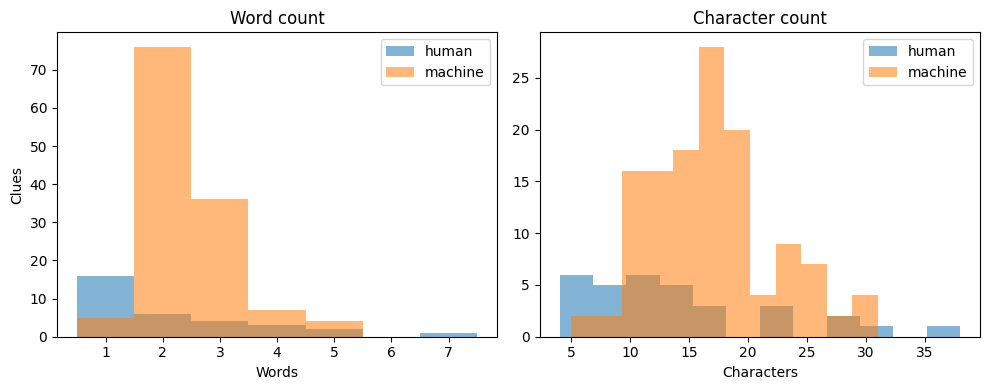

In [3]:
paired['average_word_length'] = paired.clue.map(lambda x: np.mean([len(w) for w in re.findall(r"[\w'-]+", x)]) if x else 0)
paired['has_capitalization'] = paired.clue.map(lambda x: int(any(c.isupper() for c in x)))
paired['has_punctuation'] = paired.clue.map(lambda x: int(any(c in string.punctuation for c in x)))
surface_columns = ['word_count', 'character_count', 'average_word_length', 'has_capitalization', 'has_punctuation']
surface_descriptive = paired.groupby('source')[surface_columns].agg(['count', 'mean', 'median', 'std'])
surface_round_differences = {}
for metric in surface_columns:
    pivot = paired.groupby(['round_id', 'source'])[metric].mean().unstack()
    surface_round_differences[metric] = pivot['human'] - pivot['machine']
display(surface_descriptive)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for source, frame in paired.groupby('source'):
    axes[0].hist(frame.word_count, bins=np.arange(0.5, 8.5), alpha=.55, label=source)
    axes[1].hist(frame.character_count, bins=12, alpha=.55, label=source)
axes[0].set(title='Word count', xlabel='Words', ylabel='Clues'); axes[1].set(title='Character count', xlabel='Characters')
axes[0].legend(); axes[1].legend(); fig.tight_layout()
if SAVE_ARTIFACTS: RESULTS_DIR.mkdir(parents=True, exist_ok=True); fig.savefig(RESULTS_DIR / 'surface_distributions.png', dpi=160)


## Lexical diversity and overlap

In [4]:
def tokens(text): return set(re.findall(r"[\w'-]+", text.casefold()))
def jaccard(left, right):
    union = left | right
    return len(left & right) / len(union) if union else 0.0
lexical_summary = paired.groupby('source').agg(
    clues=('clue', 'size'), unique_clues=('normalized_clue', 'nunique'))
lexical_summary['unique_clue_rate'] = lexical_summary.unique_clues / lexical_summary.clues
round_lexical = []
for round_id, frame in paired.groupby('round_id'):
    human_tokens = tokens(frame.loc[frame.source == 'human', 'clue'].iloc[0])
    machine_sets = [tokens(x) for x in frame.loc[frame.source == 'machine', 'clue']]
    human_overlap = np.mean([jaccard(human_tokens, item) for item in machine_sets])
    machine_overlap = np.mean([jaccard(machine_sets[i], machine_sets[j]) for i in range(4) for j in range(i + 1, 4)])
    round_lexical.append({'round_id': round_id, 'human_machine_jaccard': human_overlap, 'machine_machine_jaccard': machine_overlap, 'difference': human_overlap - machine_overlap})
round_lexical = pd.DataFrame(round_lexical)
display(lexical_summary); display(round_lexical.describe())


,clues,unique_clues,unique_clue_rate
source,,,
human,32,32,1.000000
machine,128,127,0.992188


,human_machine_jaccard,machine_machine_jaccard,difference
count,32.000000,32.000000,32.000000
mean,0.009570,0.015501,-0.005931
std,0.023059,0.026493,0.036887
min,0.000000,0.000000,-0.083333
25%,0.000000,0.000000,-0.014583
50%,0.000000,0.000000,0.000000
75%,0.000000,0.041667,0.000000
max,0.081250,0.083333,0.081250


## Within-round TF-IDF novelty and redundancy

In [5]:
tfidf = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4), min_df=1).fit_transform(paired.clue).toarray()
paired['tfidf_index'] = np.arange(len(paired))
round_tfidf = []
for round_id, frame in paired.groupby('round_id'):
    human_vector = tfidf[frame.loc[frame.source == 'human', 'tfidf_index'].iloc[0]]
    machine_vectors = tfidf[frame.loc[frame.source == 'machine', 'tfidf_index']]
    human_centroid_distance = cosine_distance(human_vector, machine_vectors.mean(axis=0))
    human_nearest_distance = cdist(human_vector[None, :], machine_vectors, metric='cosine').min()
    machine_nearest = [np.delete(cdist(machine_vectors[i:i+1], machine_vectors, metric='cosine')[0], i).min() for i in range(4)]
    round_tfidf.append({'round_id': round_id, 'human_centroid_distance': human_centroid_distance, 'human_nearest_distance': human_nearest_distance, 'machine_nearest_distance': np.mean(machine_nearest), 'nearest_distance_difference': human_nearest_distance - np.mean(machine_nearest)})
round_tfidf = pd.DataFrame(round_tfidf)
round_tfidf.describe()

,human_centroid_distance,human_nearest_distance,machine_nearest_distance,nearest_distance_difference
count,32.000000,32.000000,32.000000,32.000000
mean,0.909584,0.866041,0.882080,-0.016039
std,0.101708,0.154136,0.125889,0.179737
min,0.519082,0.477737,0.547797,-0.482646
25%,0.887420,0.847697,0.786239,-0.086963
50%,0.945934,0.920712,0.945671,-0.020594
75%,0.973305,0.973062,0.966630,0.037137
max,0.992393,0.990849,0.987517,0.355638


## Round-clustered confidence intervals and paired permutation tests

In [6]:
results = []
for metric in ['word_count', 'character_count']:
    values = surface_round_differences[metric].to_numpy()
    results.append(result_record(metric=f'human_minus_machine_{metric}', values=values, seed=SEED, test='round bootstrap + paired sign permutation', primary=True, p_value=paired_sign_permutation_pvalue(values, seed=SEED)))
for metric in ['human_centroid_distance', 'nearest_distance_difference']:
    values = round_tfidf[metric].to_numpy()
    results.append(result_record(metric=metric, values=values, seed=SEED, test='round bootstrap + paired sign permutation', primary=metric == 'nearest_distance_difference', p_value=paired_sign_permutation_pvalue(values, seed=SEED)))
results.append(result_record(metric='human_minus_machine_jaccard', values=round_lexical.difference, seed=SEED, test='round bootstrap + paired sign permutation', primary=False, p_value=paired_sign_permutation_pvalue(round_lexical.difference, seed=SEED)))
statistical_results = pd.DataFrame(results)
statistical_results

,metric,sample_size_rounds,estimate,effect_size,ci_95_low,ci_95_high,p_value,test,seed,primary
0,human_minus_machine_word_count,32,-0.289062,-0.185055,-0.789062,0.265625,0.321934,round bootstrap + paired sign permutation,20260805,True
1,human_minus_machine_character_count,32,-2.812500,-0.352351,-5.445312,-0.015625,0.055497,round bootstrap + paired sign permutation,20260805,True
2,human_centroid_distance,32,0.909584,8.943102,0.871648,0.940204,0.000050,round bootstrap + paired sign permutation,20260805,False
3,nearest_distance_difference,32,-0.016039,-0.089235,-0.078400,0.043135,0.623569,round bootstrap + paired sign permutation,20260805,True
4,human_minus_machine_jaccard,32,-0.005931,-0.160780,-0.018415,0.006461,0.370331,round bootstrap + paired sign permutation,20260805,False


## Grouped human-versus-machine source classifier

In [7]:
X, y, groups = paired.clue, (paired.source == 'human').astype(int), paired.round_id
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
classifier = make_pipeline(TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4), min_df=2), LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEED))
probability = cross_val_predict(classifier, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
prediction = (probability >= .5).astype(int)
classifier_metrics = {'balanced_accuracy': balanced_accuracy_score(y, prediction), 'roc_auc': roc_auc_score(y, probability)}
rng = np.random.default_rng(SEED); permutation_auc = []
for _ in range(100):
    shuffled = paired.groupby('round_id').source.transform(lambda values: rng.permutation(values.to_numpy()))
    shuffled_y = (shuffled == 'human').astype(int)
    shuffled_probability = cross_val_predict(classifier, X, shuffled_y, groups=groups, cv=cv, method='predict_proba')[:, 1]
    permutation_auc.append(roc_auc_score(shuffled_y, shuffled_probability))
classifier_metrics['permutation_p_value'] = (np.count_nonzero(np.asarray(permutation_auc) >= classifier_metrics['roc_auc']) + 1) / 101
classifier_metrics

{'balanced_accuracy': 0.5625,
 'roc_auc': 0.561767578125,
 'permutation_p_value': np.float64(0.1188118811881188)}

## Optional Nomic embedding analysis
Set `RUN_OLLAMA = True` in the setup cell after starting Ollama and pulling `nomic-embed-text`. Failure to reach Ollama produces a skip message.

In [9]:
embedding_results = None
if RUN_OLLAMA:
    vectors = ollama_embeddings(paired.clue.tolist(), cache_path=RESULTS_DIR / 'nomic_embeddings.json')
    if vectors is not None:
        embedding_rows = []
        for round_id, frame in paired.groupby('round_id'):
            human = vectors[frame.loc[frame.source == 'human', 'tfidf_index'].iloc[0]]
            machines = vectors[frame.loc[frame.source == 'machine', 'tfidf_index']]
            human_nearest = cdist(human[None, :], machines, metric='cosine').min()
            machine_nearest = np.mean([np.delete(cdist(machines[i:i+1], machines, metric='cosine')[0], i).min() for i in range(4)])
            embedding_rows.append({'round_id': round_id, 'human_nearest_distance': human_nearest, 'machine_nearest_distance': machine_nearest, 'difference': human_nearest - machine_nearest})
        embedding_results = pd.DataFrame(embedding_rows)
embedding_results

,round_id,human_nearest_distance,machine_nearest_distance,difference
0,0970a868-f8ce-42c6-8b01-230a873e0b20,0.351425,0.601292,-0.249867
1,15ad12c3-2098-4f2b-85ca-00d51dfeeceb,0.420453,0.404868,0.015585
2,19472f03-1a62-4432-a02f-6d62710f92d6,0.520657,0.347916,0.172741
3,1a21037e-3dd2-4c70-a0dc-dfbbffbef46c,0.360481,0.532017,-0.171536
4,20564311-a998-40b1-ae49-b33f853447ed,0.255537,0.483764,-0.228228
5,23372544-6c20-432e-a3b2-138f9cb452d7,0.579477,0.636553,-0.057075
6,23e4f577-9c3f-48f5-92c7-936b0ec16d1e,0.285316,0.362128,-0.076812
7,3f1f7d3d-ceea-4fce-9ec8-58edc290585e,0.590471,0.415250,0.175221
8,407ced8d-e06d-426e-8cf3-83583120bf9b,0.370857,0.511145,-0.140288
9,4dcc7feb-7898-4181-92c5-bc37b95086a0,0.470220,0.362623,0.107597


## Reproducible summary

In [12]:
summary = {'dataset_version': MANIFEST['dataset_version'], 'accounting': accounting.to_dict(), 'statistical_results': statistical_results.to_dict(orient='records'), 'classifier': classifier_metrics}
if SAVE_ARTIFACTS:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    statistical_results.to_csv(RESULTS_DIR / 'statistical_results.csv', index=False)
    save_json(RESULTS_DIR / 'summary.json', summary)
summary

{'dataset_version': '20260805_151157',
 'accounting': {'all_clues': 198,
  'all_rounds': 42,
  'paired_rounds': 32,
  'paired_human_clues': 32,
  'paired_machine_clues': 128},
 'statistical_results': [{'metric': 'human_minus_machine_word_count',
   'sample_size_rounds': 32,
   'estimate': -0.2890625,
   'effect_size': -0.18505492767869258,
   'ci_95_low': -0.7890625,
   'ci_95_high': 0.265625,
   'p_value': 0.32193390330483473,
   'test': 'round bootstrap + paired sign permutation',
   'seed': 20260805,
   'primary': True},
  {'metric': 'human_minus_machine_character_count',
   'sample_size_rounds': 32,
   'estimate': -2.8125,
   'effect_size': -0.3523514678037963,
   'ci_95_low': -5.4453125,
   'ci_95_high': -0.015625,
   'p_value': 0.05549722513874306,
   'test': 'round bootstrap + paired sign permutation',
   'seed': 20260805,
   'primary': True},
  {'metric': 'human_centroid_distance',
   'sample_size_rounds': 32,
   'estimate': 0.9095836419982275,
   'effect_size': 8.9431019336524